![Banner](../images/09_13_banner_rs_soil_moisture.png)

# Change Detection Soil Moisture from Sentinel-1

The scatterometer method of notebook 08 works for SAR too: at each 50 m pixel, the driest and
wettest backscatter of a multi-year Sentinel-1 series define 0 and 100 % relative soil moisture, and
every acquisition is placed between them. This is how the Copernicus 1 km surface soil moisture
product is made (Bauer-Marschallinger et al. 2019). This notebook applies change detection to the
2019 to 2021 Sentinel-1 cube of central Iowa, converts the relative values to volumetric soil
moisture with SoilGrids, checks them at the two in situ stations, and compares them with a second
approach that uses SAR only to distribute the coarse SMAP soil moisture within each 9 km cell.

## Overview

### The TU Wien approach for SAR

For each pixel, with backscatter `sigma0` in dB on one relative orbit:

`ms(t) = (sigma0(t) - sigma_dry) / (sigma_wet - sigma_dry)`

`sigma_dry` and `sigma_wet` are low and high percentiles of the pixel's history: the 5th and 95th
here, which are more robust to outliers than the minimum and maximum, computed from April to
November only, since frozen or snow-covered soil has the backscatter of dry soil. The method assumes that, over the
record, the pixel has been both very dry and very wet, that roughness does not change, and that
vegetation changes the backscatter much less than soil moisture does, or at least does so in the same
way every year. Their difference, the sensitivity, should be several dB for the method to work;
forests, towns and water have little sensitivity.

### From relative to volumetric

Relative soil moisture spans the observed range of the pixel. With porosity `phi` and a residual
water content `theta_r` (here the wilting point, the lowest water content soils reach outside the
surface crust), `theta = theta_r + ms (phi - theta_r)`.

### Disaggregating SMAP with SAR

The SMAP active-passive baseline algorithm (Das et al. 2014) keeps the coarse radiometer soil
moisture as the truth for each 9 km cell and distributes it with the SAR backscatter of the fine
pixels:

`theta_fine = theta_coarse + beta (sigma_fine - sigma_coarse)`

where `sigma_coarse` is the mean backscatter of the cell and `beta` (m3 m-3 per dB) is the slope of
the coarse soil moisture against `sigma_coarse` over time. The result has the accuracy of SMAP and the
spatial detail of Sentinel-1.

## Change Detection with GeoLattice

| Function | Purpose |
|---|---|
| `sm.change_detection_references` | per-pixel dry and wet references, sensitivity and number of dates |
| `sm.change_detection` | relative soil moisture, 0 to 1 |
| `sm.saxton_rawls`, `sm.relative_to_volumetric` | porosity and wilting point from texture, conversion |
| `sm.short_term_change_detection` | SMAP disaggregation with SAR (active-passive baseline) |
| `sm.sar_masks`, `sm.validation_metrics` | masks and station checks |

### Learning objectives

1. Compute dry and wet references and judge where change detection can work.
2. Produce relative and volumetric soil moisture maps at 50 m.
3. Validate the retrievals at two in situ stations.
4. Disaggregate 9 km SMAP soil moisture with Sentinel-1 and compare the two approaches.

### Data

| Dataset | Content |
|---|---|
| Sentinel-1 RTC cube (notebook 11) | VV gamma0 (dB), relative orbit 165, April to November 2019 to 2021, 50 m |
| SoilGrids 2.0 0 to 5 cm | sand, clay, organic carbon at 250 m |
| SMAP L3 Enhanced | AM soil moisture at 9 km |
| USCRN Des Moines 17 E, SCAN Ames | in situ 5 cm soil moisture |

### Contents

- Setup
- Dry and wet references
- Relative soil moisture maps
- Volumetric soil moisture
- Checking at the stations
- Disaggregating SMAP with Sentinel-1
- Summary and exercises

## Setup

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor)
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.rsense.soil_moisture as sm  # soil moisture physics, products, retrieval and validation
import sm_data as sd  # chapter helper: subsets, downloads and caches the data

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
OUT = Path("outputs")  # results written by this chapter
OUT.mkdir(exist_ok=True)  # create it if needed
print("GeoLattice", geolattice.__version__, "| data folder", sd.DATA.relative_to(sd.DATA.parents[3]))  # versions and paths

from pyproj import Transformer  # station coordinates
from rasterio.enums import Resampling  # resampling
s1 = sd.s1_cube()  # notebook 11 cube
stat = sd.static_layers()  # DEM, land cover, crops
soil_t = sd.uscrn().ts_5.resample("1D").min()  # daily minimum soil temperature at 5 cm
masks = sm.sar_masks(s1, dem=stat.dem, landcover=stat.worldcover, temperature=soil_t)  # water, urban, steep, frozen
season = s1.time.dt.month.isin(range(4, 12))  # April to November: snow-free, unfrozen soils
ok_t = ~masks.frozen & season  # usable dates
vv = s1.vv.where(masks.valid).sel(time=ok_t)  # VV in dB, valid pixels, usable dates
print(f"{vv.sizes['time']} dates from April to November with unfrozen soil, {float(masks.valid.mean()):.0%} of pixels valid")  # sample

GeoLattice 0.3.49 | data folder GeoLattice/Data/08_remote_sensing/08_13_soil_moisture


50 dates from April to November with unfrozen soil, 91% of pixels valid


## Dry and wet references

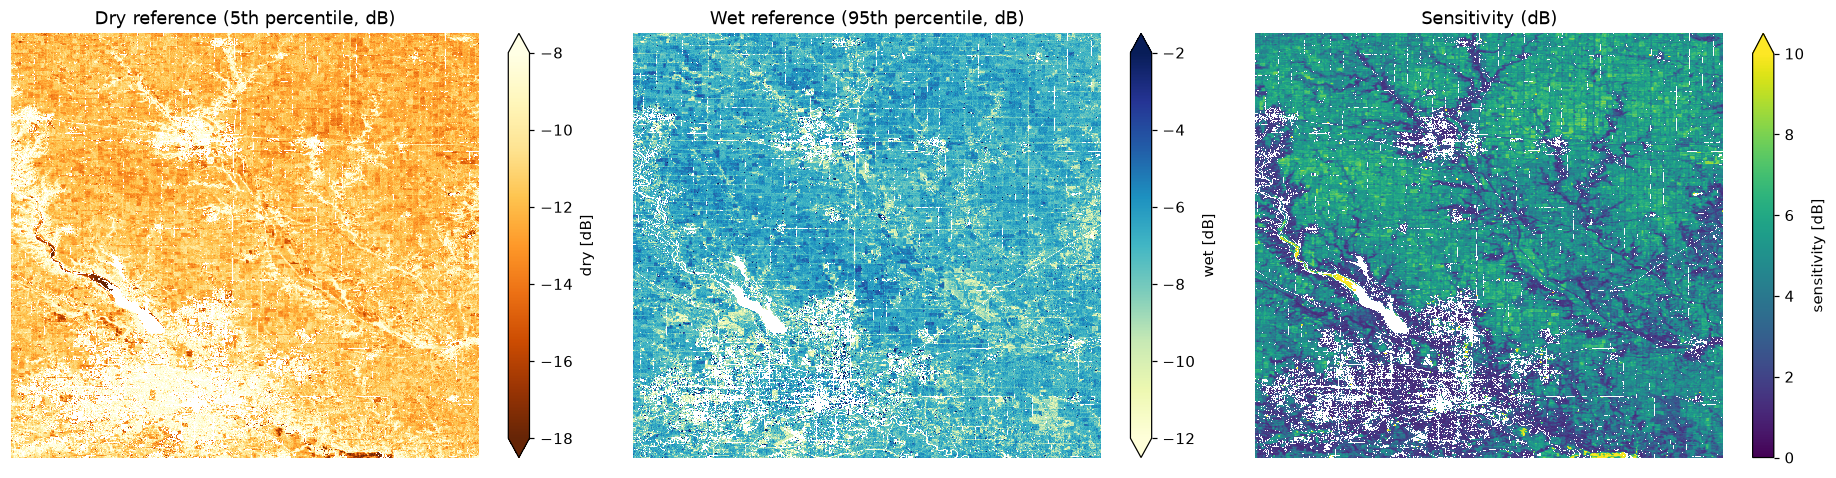

worldcover,tree cover,grassland,cropland,built-up,bare,water,wetland
median sensitivity (dB),1.8,2.9,5.2,NaN,3.9,NaN,6.6


In [2]:
ref = sm.change_detection_references(vv, dry_quantile=0.05, wet_quantile=0.95, min_obs=20)  # references
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))  # three maps
ref.dry.plot(ax=ax[0], cmap="YlOrBr_r", vmin=-18, vmax=-8); ax[0].set_title("Dry reference (5th percentile, dB)")  # dry
ref.wet.plot(ax=ax[1], cmap="YlGnBu", vmin=-12, vmax=-2); ax[1].set_title("Wet reference (95th percentile, dB)")  # wet
ref.sensitivity.plot(ax=ax[2], cmap="viridis", vmin=0, vmax=10); ax[2].set_title("Sensitivity (dB)")  # range
for a in ax: a.axis("off")  # clean maps
plt.tight_layout(); plt.show()  # draw
by_cover = ref.sensitivity.groupby(stat.worldcover.rename("worldcover")).median().to_series()  # by land cover
names = {10: "tree cover", 30: "grassland", 40: "cropland", 50: "built-up", 60: "bare", 80: "water", 90: "wetland"}  # WorldCover classes
display(by_cover.rename(index=names).rename("median sensitivity (dB)").to_frame().T.round(1))  # table

Croplands have a median sensitivity of 5.2 dB between their driest and wettest states (part of it
from crop growth and tillage, which the method cannot separate from soil moisture), and the few
wetland pixels even more; grassland has 2.9 dB and trees, which shield the soil, only 1.8 dB. Built-up
and water pixels were masked.

## Relative soil moisture maps

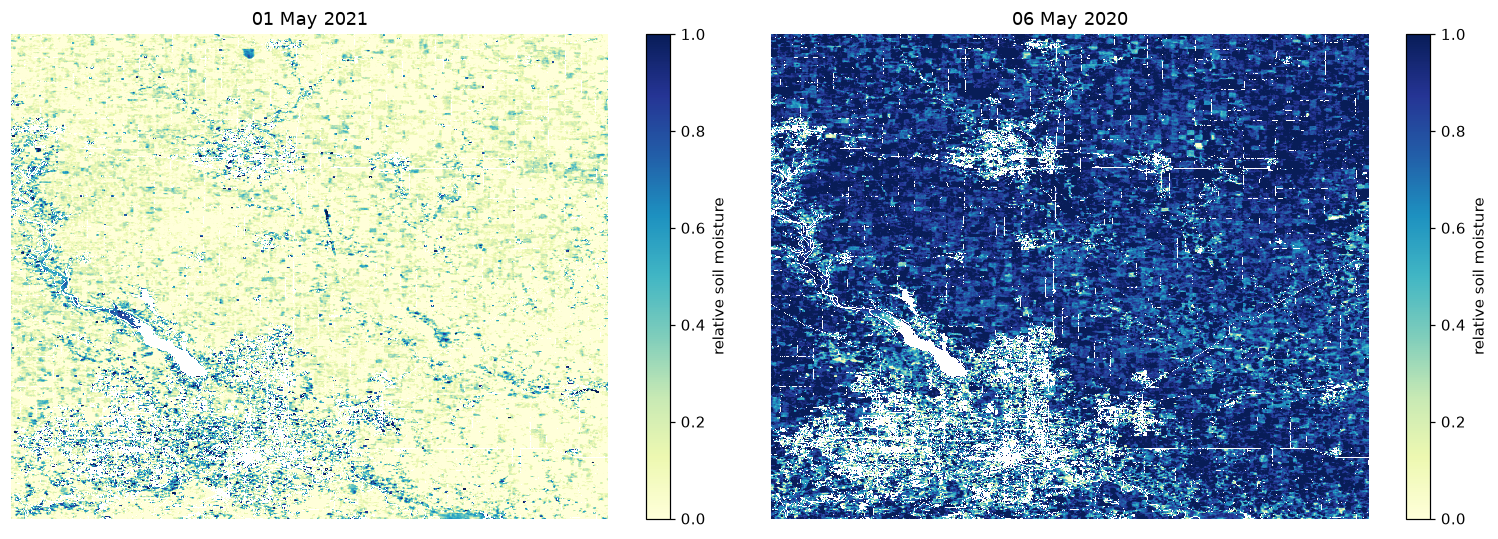

driest date 2021-05-01 (mean 0.12), wettest 2020-05-06 (mean 0.84)


In [3]:
rel = sm.change_detection(vv, references=ref)  # 0 to 1
mean_rel = rel.mean(("y", "x")).to_series()  # area mean per date
wet_day, dry_day = mean_rel.idxmax(), mean_rel.idxmin()  # extremes
fig, ax = plt.subplots(1, 2, figsize=(14, 5))  # two dates
for a, d in zip(ax, (dry_day, wet_day)):  # each date
    rel.sel(time=d).plot(ax=a, cmap="YlGnBu", vmin=0, vmax=1, cbar_kwargs={"label": "relative soil moisture"}); a.set_title(f"{pd.Timestamp(d):%d %b %Y}"); a.axis("off")  # map
plt.tight_layout(); plt.show()  # draw
print(f"driest date {pd.Timestamp(dry_day):%Y-%m-%d} (mean {mean_rel.min():.2f}), wettest {pd.Timestamp(wet_day):%Y-%m-%d} (mean {mean_rel.max():.2f})")  # extremes

The area mean of relative soil moisture ranges from 0.12 on 1 May 2021, during the dry spring of
2021, to 0.84 on 6 May 2020, after heavy spring rain. Field boundaries are visible on both dates,
because each field's tillage and crop history shape its own record.

## Volumetric soil moisture

porosity 0.48 to 0.59, wilting point 0.17 to 0.24 m3/m3


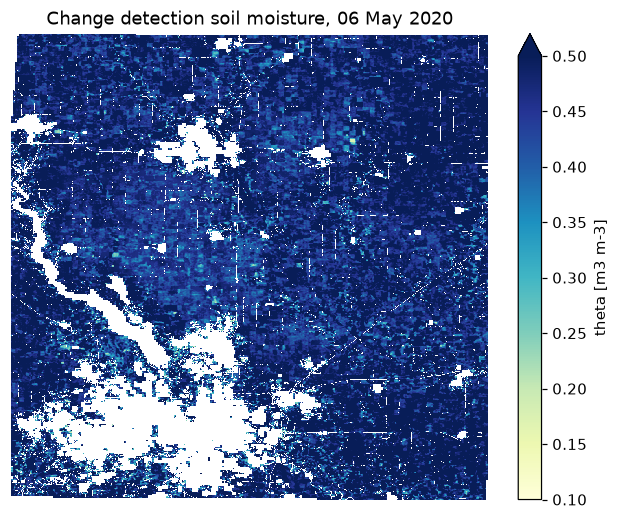

In [4]:
soil = sd.soilgrids_grid(sd.IOWA_SAR, "iowa_sar", crs="EPSG:32615").isel(depth=0)  # SoilGrids 0 to 5 cm in UTM
lim = sm.saxton_rawls(soil["sand"], soil["clay"], organic_matter=0.1724 * soil["soc"])  # pedotransfer limits (Dataset)
tmpl = vv.isel(time=0, drop=True)  # S1 grid
phi = lim["saturation"].rio.write_crs(soil.rio.crs).rio.reproject_match(tmpl, resampling=Resampling.bilinear)  # porosity on the S1 grid
wp = lim["wilting_point"].rio.write_crs(soil.rio.crs).rio.reproject_match(tmpl, resampling=Resampling.bilinear)  # wilting point
theta_cd = sm.relative_to_volumetric(rel, porosity=phi, residual=wp)  # volumetric soil moisture
print(f"porosity {float(phi.quantile(0.05)):.2f} to {float(phi.quantile(0.95)):.2f}, wilting point {float(wp.quantile(0.05)):.2f} to {float(wp.quantile(0.95)):.2f} m3/m3")  # ranges
theta_cd.sel(time=wet_day).plot(figsize=(7, 5.5), cmap="YlGnBu", vmin=0.1, vmax=0.5); plt.title(f"Change detection soil moisture, {pd.Timestamp(wet_day):%d %b %Y}"); plt.axis("off"); plt.show()  # map

## Checking at the stations

Each station is compared with the mean of the 3 x 3 pixels (150 m) around it, on the acquisition
days (the 5 cm daily mean).

,n,bias,rmse,ubrmse,pearson_r,land cover
station,,,,,,
USCRN Des Moines 17 E,45,0.109,0.149,0.102,0.281,grassland
SCAN Ames,49,0.089,0.151,0.122,0.241,cropland


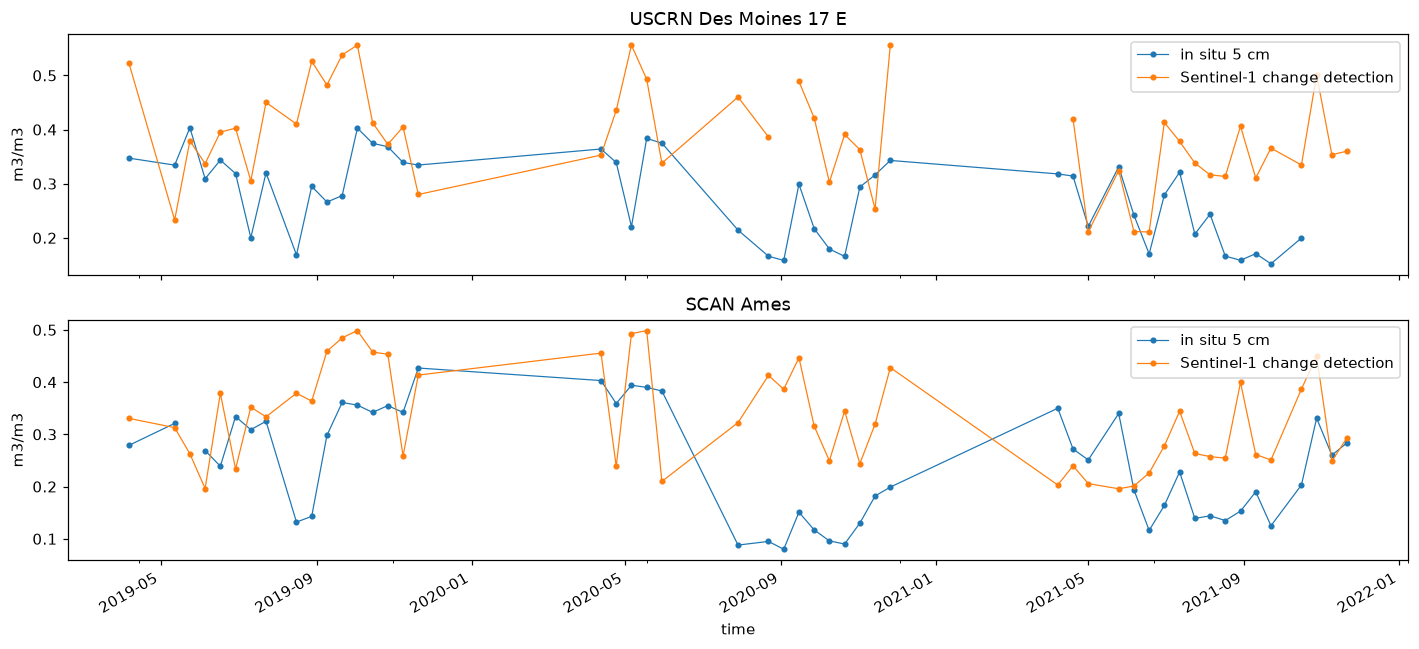

In [5]:
t = Transformer.from_crs(4326, s1.rio.crs, always_xy=True)  # lon/lat to UTM
ins = {"USCRN Des Moines 17 E": sd.uscrn().sm_5.resample("1D").mean(), "SCAN Ames": sd.scan().sm_5}  # in situ 5 cm
rows, series = [], {}  # metrics and series
for st, s in sd.STATIONS.iterrows():  # each station
    x, y = t.transform(s.lon, s.lat)  # station position
    ix, iy = int(np.abs(tmpl.x - x).argmin()), int(np.abs(tmpl.y - y).argmin())  # pixel indices
    px = theta_cd.isel(x=slice(ix - 1, ix + 2), y=slice(iy - 1, iy + 2)).mean(("y", "x")).to_series()  # 3 x 3 mean
    px.index = px.index.normalize()  # acquisition day
    ref_s = ins[st].reindex(px.index)  # in situ on those days
    m = sm.validation_metrics(ref_s, px)  # metrics
    rows.append({"station": st, **m.to_dict(), "land cover": names.get(int(stat.worldcover.isel(x=ix, y=iy)), "?")})  # row
    series[st] = pd.DataFrame({"in situ 5 cm": ref_s, "Sentinel-1 change detection": px})  # for the plot
display(pd.DataFrame(rows).set_index("station")[["n", "bias", "rmse", "ubrmse", "pearson_r", "land cover"]].round(3))  # table
fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True)  # series
for a, (st, df) in zip(ax, series.items()):  # each station
    df.plot(ax=a, marker="o", ms=3, lw=0.8); a.set_title(st); a.set_ylabel("m3/m3")  # plot
plt.tight_layout(); plt.show()  # draw

## Disaggregating SMAP with Sentinel-1

SMAP's AM retrieval of the same day (or the day before or after) gives the 9 km soil moisture; the
SAR backscatter distributes it inside each cell. All successful SMAP retrievals are used here
(`level="all"`): the cells of both stations contain parts of Des Moines and Ames or lakes, which the
"recommended quality" bit excludes, although the retrieval itself succeeded.

beta: median 0.0263 m3/m3 per dB


n   bias  ubrmse  pearson_r
station               method                                                  
USCRN Des Moines 17 E SMAP disaggregated with S1  41 -0.076   0.052      0.736
                      S1 change detection         45  0.109   0.102      0.281
SCAN Ames             SMAP disaggregated with S1  40 -0.072   0.099      0.325
                      S1 change detection         49  0.089   0.122      0.241

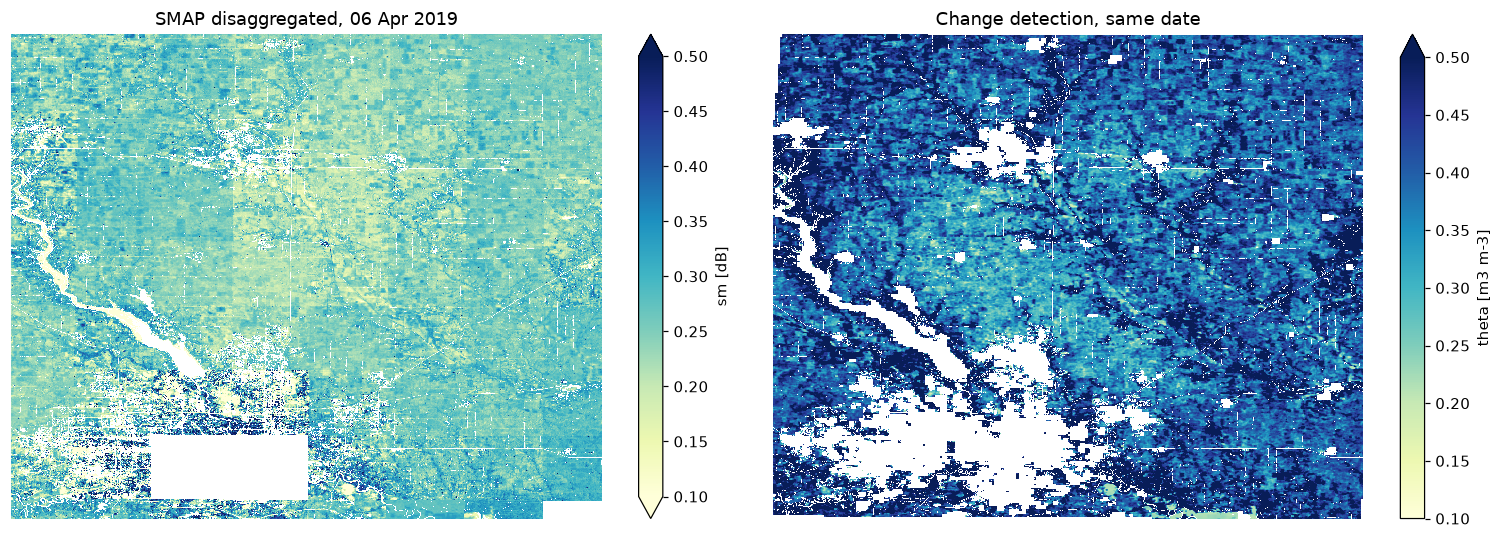

In [6]:
smap = sm.daily_cube(sm.mask_quality(sd.ease2_clip(sd.smap_l3e(), (-94.1, 41.3, -93.0, 42.4)).sel(time=slice("2019", "2021")), level="all")).sm  # SMAP 9 km, all successful retrievals
days = pd.DatetimeIndex(vv.time.values).normalize()  # S1 acquisition days
coarse = smap.reindex(time=days, method="nearest", tolerance=pd.Timedelta(days=1))  # SMAP on the S1 days (within a day)
coarse = coarse.assign_coords(time=vv.time.values).rio.write_crs("EPSG:6933")  # same time stamps as the SAR cube
ap = sm.short_term_change_detection(vv, coarse, min_obs=15)  # disaggregation
print(f"beta: median {float(ap.beta.median()):.4f} m3/m3 per dB")  # sensitivity of SMAP to the cell backscatter
rows = []  # station metrics of both approaches
for st, s in sd.STATIONS.iterrows():  # each station
    x, y = t.transform(s.lon, s.lat)  # position
    ix, iy = int(np.abs(tmpl.x - x).argmin()), int(np.abs(tmpl.y - y).argmin())  # pixel
    px = ap.sm.isel(x=slice(ix - 1, ix + 2), y=slice(iy - 1, iy + 2)).mean(("y", "x")).to_series()  # 3 x 3 mean
    px.index = px.index.normalize()  # days
    rows.append({"station": st, "method": "SMAP disaggregated with S1", **sm.validation_metrics(ins[st].reindex(px.index), px).to_dict()})  # row
    rows.append({"station": st, "method": "S1 change detection", **sm.validation_metrics(series[st]["in situ 5 cm"], series[st]["Sentinel-1 change detection"]).to_dict()})  # row
display(pd.DataFrame(rows).set_index(["station", "method"])[["n", "bias", "ubrmse", "pearson_r"]].round(3))  # table
fig, ax = plt.subplots(1, 2, figsize=(14, 5))  # one date, two methods
d = ap.sm.time.values[np.nanargmax(ap.sm.notnull().mean(("y", "x")).values)]  # date with best coverage
ap.sm.sel(time=d).plot(ax=ax[0], cmap="YlGnBu", vmin=0.1, vmax=0.5); ax[0].set_title(f"SMAP disaggregated, {pd.Timestamp(d):%d %b %Y}"); ax[0].axis("off")  # AP map
theta_cd.sel(time=d).plot(ax=ax[1], cmap="YlGnBu", vmin=0.1, vmax=0.5); ax[1].set_title("Change detection, same date"); ax[1].axis("off")  # CD map
plt.tight_layout(); plt.show()  # draw
xr.Dataset({"theta_cd": theta_cd, "rel_cd": rel, "theta_ap": ap.sm}).astype("float32").to_netcdf(OUT / "s1_soil_moisture_iowa_2019_2021.nc")  # saved for notebooks 14, 15 and 20

At the USCRN station the disaggregated SMAP has an ubRMSE of 0.052 m3 m-3 and a correlation of 0.74,
against 0.10 and 0.28 for change detection; at SCAN Ames both are weaker (ubRMSE 0.10 and 0.12, R 0.33
and 0.24). Change detection is too wet by about 0.1 m3 m-3 (the porosity of these organic-rich topsoils,
0.48 to 0.59, sets its upper end), the disaggregation too dry by about 0.07, the known dry bias of SMAP
over these Iowa soils. The two approaches answer different questions. Change detection needs no other data but inherits
every non-soil change in backscatter (crop growth, tillage, residue), and its range is set by the
pixel's history. The disaggregation keeps the SMAP soil moisture of each 9 km cell and uses the SAR
only for the spatial pattern within it, so its errors at the stations are close to those of SMAP
itself.

## Summary and exercises

- Change detection references are percentiles of each pixel's history; croplands have the
  largest sensitivity, forests and towns the smallest.
- Relative soil moisture converts to volumetric water content with SoilGrids porosity and wilting
  point.
- At the two stations the change detection retrievals follow the seasonal drying but with large
  scatter (R 0.24 to 0.28, ubRMSE 0.10 to 0.12): crops, tillage and the scale of one sensor against
  150 m all add error.
- Disaggregating SMAP with Sentinel-1 keeps the accuracy of SMAP and adds 50 m spatial detail; at the
  USCRN station it reaches R 0.74 and ubRMSE 0.052 m3 m-3.

**Exercises**

1. Use the 1st and 99th percentiles as references. Which maps change most?
2. Recompute the references from the April to May and October to November dates only (little
   vegetation). Do the station metrics improve?
3. Compute change detection from VH instead of VV and explain the result.